In [345]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [346]:
df = pd.read_csv('/kaggle/input/datasets/sabiha1134/heartdisease-prediction/Heart_Disease.csv')

In [347]:
print(df.head())

   age     sex   chest_pain_type  resting_blood_pressure  cholestoral  \
0   62  Female    Typical angina                     124          209   
1   53  Female  Non-anginal pain                     128          216   
2   55    Male    Typical angina                     160          289   
3   50  Female   Atypical angina                     120          244   
4   48    Male    Typical angina                     130          256   

      fasting_blood_sugar               rest_ecg  Max_heart_rate  \
0    Lower than 120 mg/ml  ST-T wave abnormality             163   
1    Lower than 120 mg/ml                 Normal             115   
2    Lower than 120 mg/ml                 Normal             145   
3    Lower than 120 mg/ml  ST-T wave abnormality             162   
4  Greater than 120 mg/ml                 Normal             150   

  exercise_induced_angina  oldpeak        slope        thalassemia  BMI  \
0                      No      0.0  Downsloping       Fixed Defect   20   
1 

In [348]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      205 non-null    int64  
 1   sex                      205 non-null    object 
 2   chest_pain_type          205 non-null    object 
 3   resting_blood_pressure   205 non-null    int64  
 4   cholestoral              205 non-null    int64  
 5   fasting_blood_sugar      205 non-null    object 
 6   rest_ecg                 205 non-null    object 
 7   Max_heart_rate           205 non-null    int64  
 8   exercise_induced_angina  205 non-null    object 
 9   oldpeak                  205 non-null    float64
 10  slope                    205 non-null    object 
 11  thalassemia              205 non-null    object 
 12  BMI                      205 non-null    int64  
 13  Smoking                  205 non-null    int64  
 14  Exercise_Level           2

In [349]:
np.random.seed(42)
df['BMI'] = np.random.randint(18, 35, size=len(df))
df['Smoking'] = np.random.randint(0, 2, size=len(df))
df['Exercise_Level'] = np.random.randint(1, 4, size=len(df))

In [350]:
numeric_cols = ['age', 'resting_blood_pressure', 'cholestoral', 'Max_heart_rate', 'oldpeak', 
                'BMI', 'Smoking', 'Exercise_Level']
categorical_cols = ['sex', 'chest_pain_type', 'rest_ecg', 'exercise_induced_angina', 'thalassemia']

# Clean numeric columns (extract numbers if text exists)
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col].astype(str).str.extract(r'(\d+\.?\d*)')[0], errors='coerce')


print(df.columns)   

# Separate features & target
X = df.drop(['Risk_Level', 'Heart_Risk_%'], axis=1)  
y = df['Risk_Level']                                  
                                    

# Numeric pipeline
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical pipeline
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

# Final pipeline with LogisticRegression
clf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])


Index(['age', 'sex', 'chest_pain_type', 'resting_blood_pressure',
       'cholestoral', 'fasting_blood_sugar', 'rest_ecg', 'Max_heart_rate',
       'exercise_induced_angina', 'oldpeak', 'slope', 'thalassemia', 'BMI',
       'Smoking', 'Exercise_Level', 'Heart_Risk_%', 'Risk_Level'],
      dtype='object')


In [351]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

clf.fit(X_train, y_train)

probs = clf.predict_proba(X_test)
heart_risk_percent = probs[:,1]*100

def risk_level(p):
    if p < 30:
        return "Low Risk"
    elif p < 70:
        return "Medium Risk"
    else:
        return "High Risk"

for i in range(10):
    print(f"Patient {i+1}: {heart_risk_percent[i]:.2f}% → {risk_level(heart_risk_percent[i])}")

Patient 1: 0.00% → Low Risk
Patient 2: 97.80% → High Risk
Patient 3: 56.82% → Medium Risk
Patient 4: 0.00% → Low Risk
Patient 5: 99.93% → High Risk
Patient 6: 0.63% → Low Risk
Patient 7: 98.11% → High Risk
Patient 8: 87.26% → High Risk
Patient 9: 0.00% → Low Risk
Patient 10: 0.17% → Low Risk


In [352]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = clf.predict(X_test)

acc_percent = round(accuracy_score(y_test, y_pred) * 100, 2)
print(f"Accuracy: {acc_percent}%")

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

report = classification_report(y_test, y_pred, digits=2)
print("Classification Report:\n", report)


Accuracy: 90.24%
Confusion Matrix:
[[13  0  2]
 [ 0 17  0]
 [ 1  1  7]]
Classification Report:
               precision    recall  f1-score   support

   High Risk       0.93      0.87      0.90        15
    Low Risk       0.94      1.00      0.97        17
 Medium Risk       0.78      0.78      0.78         9

    accuracy                           0.90        41
   macro avg       0.88      0.88      0.88        41
weighted avg       0.90      0.90      0.90        41



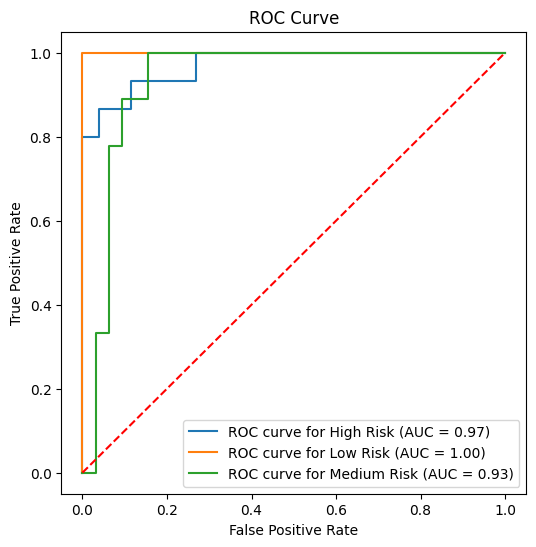

In [353]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

classes = clf.classes_
y_test_bin = label_binarize(y_test, classes=classes)
n_classes = y_test_bin.shape[1]

y_prob = clf.predict_proba(X_test)

plt.figure(figsize=(6,6))
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'ROC curve for {classes[i]} (AUC = {roc_auc:.2f})')

plt.plot([0,1],[0,1], color='red', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()


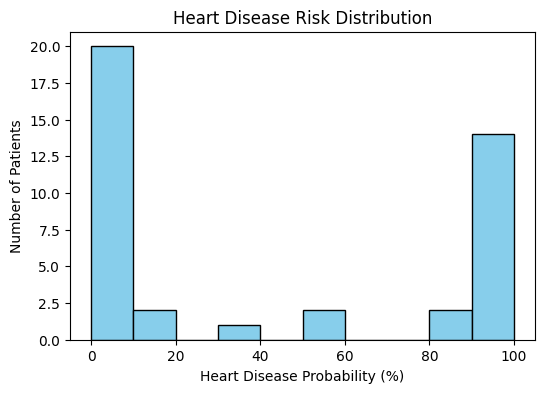

In [354]:
plt.figure(figsize=(6,4))
plt.hist(heart_risk_percent, bins=10, color='skyblue', edgecolor='black')
plt.xlabel('Heart Disease Probability (%)')
plt.ylabel('Number of Patients')
plt.title('Heart Disease Risk Distribution')
plt.show()

In [355]:
X_test_copy = X_test.copy()
X_test_copy['Heart_Risk_%'] = heart_risk_percent
X_test_copy['Risk_Level'] = [risk_level(p) for p in heart_risk_percent]

X_test_copy.to_csv('/kaggle/working/HeartDisease_Predictions.csv', index=False)

import os
print(os.listdir('/kaggle/working'))


['.virtual_documents', 'HeartDisease_Predictions.csv']


In [356]:
import pandas as pd
df_result = pd.read_csv('/kaggle/input/datasets/sabiha1134/heartdisease-prediction/Heart_Disease.csv')
df_result.head(10)  

,age,sex,chest_pain_type,resting_blood_pressure,cholestoral,fasting_blood_sugar,rest_ecg,Max_heart_rate,exercise_induced_angina,oldpeak,slope,thalassemia,BMI,Smoking,Exercise_Level,Heart_Risk_%,Risk_Level
0,62,Female,Typical angina,124,209,Lower than 120 mg/ml,ST-T wave abnormality,163,No,0.0,Downsloping,Fixed Defect,20,1,3,92.461004,High Risk
1,53,Female,Non-anginal pain,128,216,Lower than 120 mg/ml,Normal,115,No,0.0,Downsloping,No,22,0,1,82.800330,High Risk
2,55,Male,Typical angina,160,289,Lower than 120 mg/ml,Normal,145,Yes,0.8,Flat,Reversable Defect,30,0,3,2.868630,Low Risk
3,50,Female,Atypical angina,120,244,Lower than 120 mg/ml,ST-T wave abnormality,162,No,1.1,Downsloping,Fixed Defect,19,1,1,96.219293,High Risk
4,48,Male,Typical angina,130,256,Greater than 120 mg/ml,Normal,150,Yes,0.0,Downsloping,Reversable Defect,33,0,3,11.197133,Low Risk
5,74,Female,Atypical angina,120,269,Lower than 120 mg/ml,Normal,121,Yes,0.2,Downsloping,Fixed Defect,30,0,1,75.574289,High Risk
6,64,Male,Typical angina,120,246,Lower than 120 mg/ml,Normal,96,Yes,2.2,Upsloping,Fixed Defect,20,1,1,2.883586,Low Risk
7,67,Male,Typical angina,120,229,Lower than 120 mg/ml,Normal,129,Yes,2.6,Flat,Reversable Defect,29,1,1,1.224043,Low Risk
8,48,Male,Non-anginal pain,124,255,Greater than 120 mg/ml,ST-T wave abnormality,175,No,0.0,Downsloping,Fixed Defect,22,1,1,95.313547,High Risk
9,70,Male,Typical angina,145,174,Lower than 120 mg/ml,ST-T wave abnormality,125,Yes,2.6,Upsloping,Reversable Defect,31,1,1,1.635459,Low Risk


In [357]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

In [358]:
# Logistic Regression 
log_clf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])
log_clf.fit(X_train, y_train)
y_pred_log = log_clf.predict(X_test)
log_accuracy = round(accuracy_score(y_test, y_pred_log) * 100, 2)
print("Logistic Regression Accuracy:", log_accuracy, "%")

Logistic Regression Accuracy: 90.24 %


In [359]:
# Random Forest 
rf_clf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])
rf_clf.fit(X_train, y_train)
y_pred_rf = rf_clf.predict(X_test)
rf_accuracy = round(accuracy_score(y_test, y_pred_rf) * 100, 2)
print("Random Forest Accuracy:", rf_accuracy, "%")

Random Forest Accuracy: 85.37 %


In [360]:
# SVM 
svm_clf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', SVC(probability=True, kernel="rbf"))
])
svm_clf.fit(X_train, y_train)
y_pred_svm = svm_clf.predict(X_test)
svm_accuracy = round(accuracy_score(y_test, y_pred_svm) * 100, 2)
print("SVM Accuracy:", svm_accuracy, "%")

SVM Accuracy: 90.24 %


In [361]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score


In [362]:
# Decision Tree
dt_clf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42))
])
dt_clf.fit(X_train, y_train)
y_pred_dt = dt_clf.predict(X_test)
score_dt = round(accuracy_score(y_test, y_pred_dt) * 100, 2)
print("Decision Tree Accuracy:", score_dt, "%")

Decision Tree Accuracy: 80.49 %


In [363]:
# KNN 
knn_clf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=7))
])
knn_clf.fit(X_train, y_train)
y_pred_knn = knn_clf.predict(X_test)
score_knn = round(accuracy_score(y_test, y_pred_knn) * 100, 2)
print("KNN Accuracy:", score_knn, "%")


KNN Accuracy: 85.37 %


In [364]:
# Neural Network
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

df = pd.read_csv('/kaggle/input/datasets/sabiha1134/heartdisease-prediction/Heart_Disease.csv')

np.random.seed(42)
df['BMI'] = np.random.randint(18, 35, size=len(df))
df['Smoking'] = np.random.randint(0, 2, size=len(df))
df['Exercise_Level'] = np.random.randint(1, 4, size=len(df))


numeric_cols = ['age','resting_blood_pressure','cholestoral','Max_heart_rate','oldpeak',
                'BMI','Smoking','Exercise_Level']
categorical_cols = ['sex','chest_pain_type','rest_ecg','exercise_induced_angina','thalassemia']


for col in numeric_cols:
    df[col] = pd.to_numeric(df[col].astype(str).str.extract(r'(\d+\.?\d*)')[0], errors='coerce')


X = df.drop(['Risk_Level','Heart_Risk_%'], axis=1)
y = df['Risk_Level']   


preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_processed = preprocessor.fit_transform(X)

y_encoded = pd.get_dummies(y).values

X_train_nn, X_test_nn, Y_train_nn, Y_test_nn = train_test_split(
    X_processed, y_encoded, test_size=0.2, random_state=42
)

model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_nn.shape[1],)),
    Dense(32, activation='relu'),
    Dense(Y_train_nn.shape[1], activation='softmax')   
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history = model.fit(X_train_nn, Y_train_nn, epochs=50, batch_size=16,
                    validation_split=0.2, verbose=1)

loss, acc = model.evaluate(X_test_nn, Y_test_nn, verbose=0)

score_mlp = round(acc*100, 2)

print(f"Neural Network Accuracy: {score_mlp}%")


Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 151ms/step - accuracy: 0.3308 - loss: 1.1199 - val_accuracy: 0.3636 - val_loss: 1.0550
Epoch 2/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5113 - loss: 1.0245 - val_accuracy: 0.4545 - val_loss: 0.9771
Epoch 3/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6135 - loss: 0.9164 - val_accuracy: 0.5152 - val_loss: 0.9100
Epoch 4/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7776 - loss: 0.8460 - val_accuracy: 0.6667 - val_loss: 0.8514
Epoch 5/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7782 - loss: 0.7491 - val_accuracy: 0.6970 - val_loss: 0.7979
Epoch 6/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7558 - loss: 0.7549 - val_accuracy: 0.6970 - val_loss: 0.7454
Epoch 7/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7647 - loss: 0.6353 - val_accuracy: 0.7273 - val_loss: 0.6963
Epoch 8/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7739 - loss: 0.5900 - val_accuracy: 0.7273 - val_loss: 0.6486
Epoch 9/50

In [365]:
comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'SVM',
        'Decision Tree',
        'KNN',
        'Neural Network'
    ],
    'Accuracy (%)': [
        log_accuracy,   
        rf_accuracy,    
        svm_accuracy,   
        score_dt,       
        score_knn,      
        score_mlp       
    ]
})

print(comparison)


                 Model  Accuracy (%)
0  Logistic Regression         90.24
1        Random Forest         85.37
2                  SVM         90.24
3        Decision Tree         80.49
4                  KNN         85.37
5       Neural Network         95.12


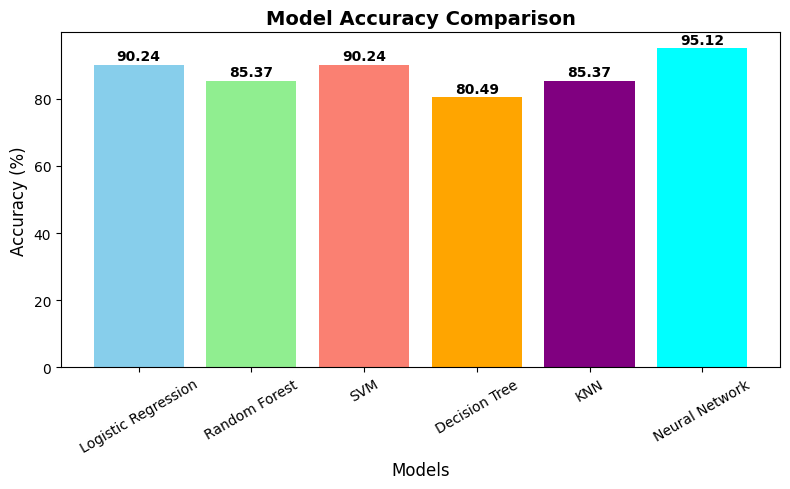

In [366]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))


bars = plt.bar(comparison['Model'], comparison['Accuracy (%)'],
               color=['skyblue','lightgreen','salmon','orange','purple','cyan'])


for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.5,
             f'{height:.2f}', ha='center', va='bottom', fontsize=10, fontweight='bold')


plt.xlabel('Models', fontsize=12)
plt.ylabel('Accuracy (%)', fontsize=12)
plt.title('Model Accuracy Comparison', fontsize=14, fontweight='bold')


plt.xticks(rotation=30, fontsize=10)

plt.tight_layout()
plt.show()


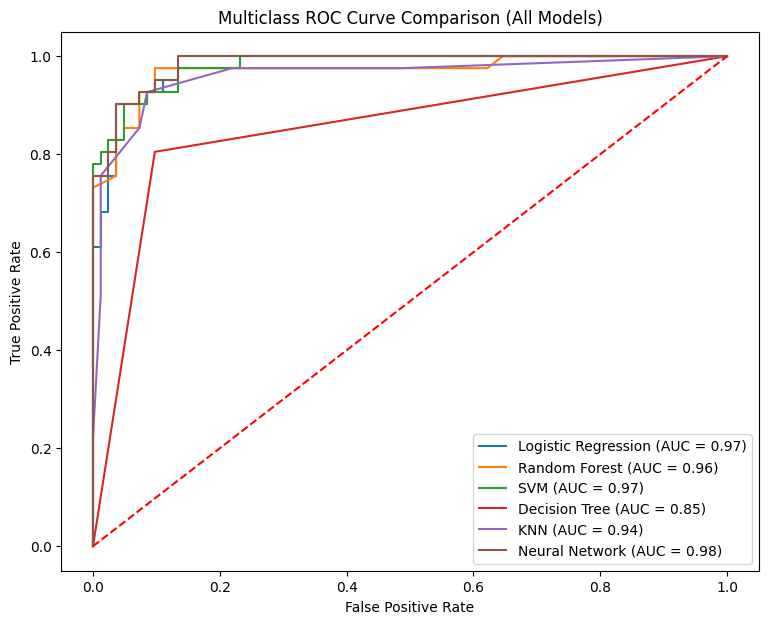

In [367]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score
import matplotlib.pyplot as plt

classes = np.unique(y_test)   
y_test_bin = label_binarize(y_test, classes=classes)
n_classes = y_test_bin.shape[1]

models = {
    "Logistic Regression": log_clf,
    "Random Forest": rf_clf,
    "SVM": svm_clf,
    "Decision Tree": dt_clf,
    "KNN": knn_clf,
    "Neural Network": mlp_clf
}


plt.figure(figsize=(9,7))

for name, model in models.items():
    probs = model.predict_proba(X_test)
    
    
    auc_score = roc_auc_score(y_test_bin, probs, average="macro", multi_class="ovr")
    

    fpr, tpr, _ = roc_curve(y_test_bin.ravel(), probs.ravel())
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.2f})")

plt.plot([0,1],[0,1],'--',color='red')  
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass ROC Curve Comparison (All Models)')
plt.legend()
plt.show()
